
# Healthcare Spending and Life Expectancy Around the World

Healthcare spending varies significantly across countries, but does spending more necessarily mean people live longer?

In this project, I explore the relationship between healthcare expenditure per person and life expectancy across countries using data from the World Bank.

I expect to find a positive relationship between healthcare spending and life expectancy, although other factors, such as income, education, and living conditions, likely play important roles too.



## Data Sources

I use two datasets from the World Bank's World Development Indicators database:

1. **Current health expenditure per capita (current US$):** Measures average healthcare spending per person in each country. [Source](https://data.worldbank.org/indicator/SH.XPD.CHEX.PC.CD)

2. **Life expectancy at birth, total (years):** Measures how many years a newborn would be expected to live based on current mortality rates. [Source](https://data.worldbank.org/indicator/SP.DYN.LE00.IN)

Both datasets contain country-level information, allowing me to compare healthcare spending and life expectancy across countries.


## Loading and Exploring the Data

I'll start by importing the necessary Python libraries, then load both datasets from the World Bank to see what information is available.

In [22]:
import pandas as pd
import matplotlib.pyplot as plt


### Dataset 1: Healthcare Spending

First, I'll load healthcare spending per capita data from the World Bank. This measures how much is spent on healthcare per person in each country, in current U.S. dollars.


In [23]:
# Load healthcare spending data from the World Bank
import requests

url = "https://api.worldbank.org/v2/country/all/indicator/SH.XPD.CHEX.PC.CD?format=json&per_page=20000"

response = requests.get(url)
response.raise_for_status()

health_data = response.json()[1]
health_df = pd.DataFrame(health_data)

health_df.head()

,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'SH.XPD.CHEX.PC.CD', 'value': 'Current ...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2025,NaN,,,2
1,"{'id': 'SH.XPD.CHEX.PC.CD', 'value': 'Current ...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2024,NaN,,,2
2,"{'id': 'SH.XPD.CHEX.PC.CD', 'value': 'Current ...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,88.485585,,,2
3,"{'id': 'SH.XPD.CHEX.PC.CD', 'value': 'Current ...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,92.035288,,,2
4,"{'id': 'SH.XPD.CHEX.PC.CD', 'value': 'Current ...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,92.350333,,,2



### Dataset 2: Life Expectancy

Next, I'll load life expectancy data from the World Bank. This measures the expected number of years a newborn would live based on current mortality rates.

I'll use this dataset alongside healthcare spending to explore their relationship across countries.

In [24]:
# Load life expectancy data from the World Bank
life_url = (
    "https://api.worldbank.org/v2/country/all/indicator/"
    "SP.DYN.LE00.IN?format=json&per_page=20000"
)

life_response = requests.get(life_url)
life_response.raise_for_status()

life_data = life_response.json()[1]
life_df = pd.DataFrame(life_data)

life_df.head()

,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2025,NaN,,,0
1,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2024,65.349930,,,0
2,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2023,65.146228,,,0
3,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2022,64.487152,,,0
4,"{'id': 'SP.DYN.LE00.IN', 'value': 'Life expect...","{'id': 'ZH', 'value': 'Africa Eastern and Sout...",AFE,2021,62.979999,,,0



## Data Cleaning and Preparation

Before combining the two datasets, I'll check which years have available data. Since the World Bank indicators are updated at different times, I want to select a year with good coverage in both datasets.

I'll also need to remove missing values and exclude regional aggregates so that each observation represents an individual country.

In [25]:
# Check the number of available observations by year
health_counts = health_df.groupby("date")["value"].count()
life_counts = life_df.groupby("date")["value"].count()

availability = pd.DataFrame(
    {"Healthcare Spending": health_counts, "Life Expectancy": life_counts}
)

availability.tail(10)

,Healthcare Spending,Life Expectancy
date,,
2016,239,265
2017,240,265
2018,241,265
2019,241,265
2020,241,265
2021,240,265
2022,239,265
2023,239,265
2024,24,265



### Selecting and Combining the Data

I'll use 2023 because it is the most recent year with good data coverage for both indicators.

Before merging the datasets, I'll remove regional and income-group aggregates, keep only countries with available data, and select the columns needed for the analysis.

I'll then merge the datasets using their three-letter country codes so that healthcare spending and life expectancy are matched correctly.

In [26]:
# Get country codes, excluding regional and income-group aggregates
country_url = "https://api.worldbank.org/v2/country?format=json&per_page=500"

country_response = requests.get(country_url)
country_response.raise_for_status()

countries = pd.DataFrame(country_response.json()[1])

valid_codes = countries.loc[countries["region"].apply(lambda x: x["id"] != "NA"), "id"]

# Select 2023 data and keep the necessary columns
health_2023 = health_df[
    (health_df["date"] == "2023")
    & (health_df["value"].notna())
    & (health_df["countryiso3code"].isin(valid_codes))
][["countryiso3code", "value"]].copy()

life_2023 = life_df[
    (life_df["date"] == "2023")
    & (life_df["value"].notna())
    & (life_df["countryiso3code"].isin(valid_codes))
][["countryiso3code", "value"]].copy()

# Rename the value columns
health_2023 = health_2023.rename(columns={"value": "health_spending"})

life_2023 = life_2023.rename(columns={"value": "life_expectancy"})

# Merge both datasets by country
merged_df = pd.merge(health_2023, life_2023, on="countryiso3code", how="inner")

merged_df.head()

,countryiso3code,health_spending,life_expectancy
0,AFG,59.067707,66.035
1,ALB,590.627991,79.602
2,DZA,233.379471,76.261
3,AND,3605.197998,84.041
4,AGO,76.071182,64.617



### Checking the Merged Dataset

Now that the datasets are combined, I'll check how many countries are included and whether any missing values remain. This will help me confirm that the data are ready for visualization.

In [27]:
# Check the number of countries and missing values
print("Number of countries:", len(merged_df))

print("\nMissing values:")
print(merged_df.isnull().sum())

# Summary statistics
merged_df[["health_spending", "life_expectancy"]].describe()

Number of countries: 191

Missing values:
countryiso3code    0
health_spending    0
life_expectancy    0
dtype: int64


,health_spending,life_expectancy
count,191.000000,191.000000
mean,1433.836658,73.088140
std,2328.266823,7.193140
min,17.440035,54.462000
25%,94.382629,67.369000
50%,470.403473,73.490000
75%,1611.698486,78.198268
max,13473.193359,86.372000



## Visualizing the Relationship

Now that both datasets are combined, I'll create a scatterplot to explore the relationship between healthcare spending per capita and life expectancy in 2023.

Each point represents a country. Healthcare spending is shown on the horizontal axis, while life expectancy is shown on the vertical axis.

I'm interested in whether countries that spend more on healthcare generally have longer life expectancy, and whether there are any noticeable exceptions.

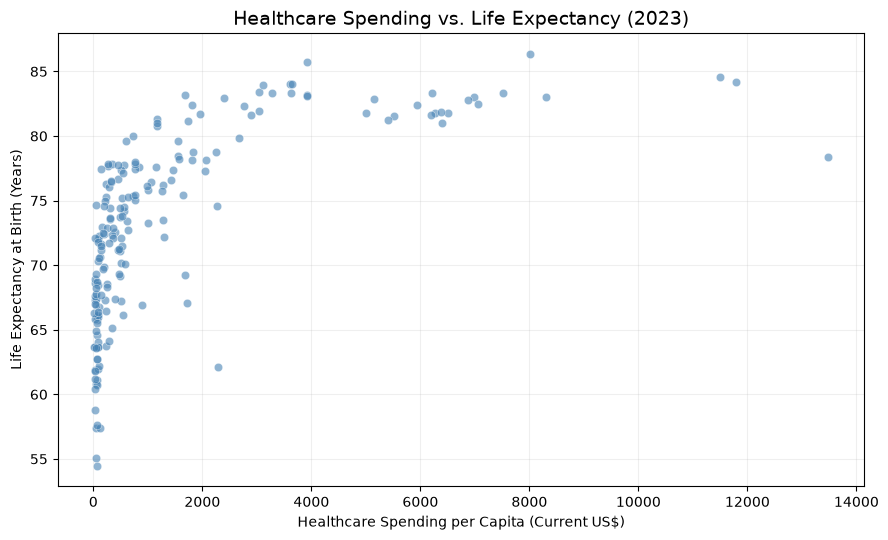

In [28]:
# Scatterplot of healthcare spending and life expectancy
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    merged_df["health_spending"],
    merged_df["life_expectancy"],
    alpha=0.6,
    color="steelblue",
    edgecolors="white",
    linewidth=0.4,
)

ax.set_title("Healthcare Spending vs. Life Expectancy (2023)", fontsize=14)
ax.set_xlabel("Healthcare Spending per Capita (Current US$)")
ax.set_ylabel("Life Expectancy at Birth (Years)")

ax.grid(True, alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### A Closer Look at the Relationship

The first scatterplot suggests a positive relationship between healthcare spending and life expectancy, but most countries are clustered on the left side of the chart.

To make the pattern easier to see, I'll use a logarithmic scale for healthcare spending. This spreads out countries with lower spending while keeping high-spending countries visible.

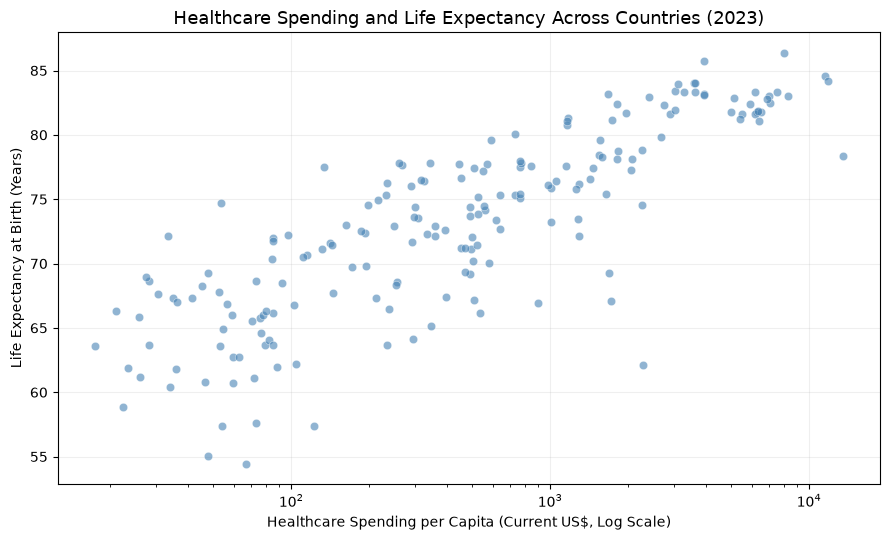

In [29]:
# Scatterplot with a logarithmic spending scale
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    merged_df["health_spending"],
    merged_df["life_expectancy"],
    alpha=0.6,
    color="steelblue",
    edgecolors="white",
    linewidth=0.4,
)

ax.set_xscale("log")

ax.set_title(
    "Healthcare Spending and Life Expectancy Across Countries (2023)", fontsize=13
)
ax.set_xlabel("Healthcare Spending per Capita (Current US$, Log Scale)")
ax.set_ylabel("Life Expectancy at Birth (Years)")

ax.grid(True, alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Measuring the Relationship

The scatterplot suggests that countries with higher healthcare spending generally have longer life expectancy.

To better understand the strength of this relationship, I'll calculate the Pearson correlation coefficient. This measures the strength of a linear relationship between two variables, ranging from -1 to 1.

I'll calculate it using both the original spending values and their logarithms, since the scatterplots suggest that the relationship may not be linear.

In [30]:
import numpy as np

# Calculate correlations
correlation = merged_df["health_spending"].corr(merged_df["life_expectancy"])

log_correlation = np.log10(merged_df["health_spending"]).corr(
    merged_df["life_expectancy"]
)

print(f"Correlation (original spending): {correlation:.3f}")
print(f"Correlation (log spending): {log_correlation:.3f}")

Correlation (original spending): 0.626
Correlation (log spending): 0.828



## Findings and Discussion

The results show a clear positive relationship between healthcare spending and life expectancy across the 191 countries included in the analysis.

The Pearson correlation between healthcare spending per capita and life expectancy is **0.626**, indicating a moderately strong positive linear relationship. When healthcare spending is log-transformed, the correlation increases to **0.828**, suggesting that the relationship is more nearly linear on a logarithmic scale.

One interesting finding is that the relationship appears to flatten at higher spending levels. Countries spending relatively little on healthcare show considerable variation in life expectancy, while many higher-spending countries cluster around 80–85 years.

There are also exceptions. Some countries spend substantially more on healthcare without achieving the highest life expectancy. This suggests that spending alone does not explain differences in health outcomes.

## Limitations

There are several limitations to this analysis.

First, correlation does not imply causation. Higher healthcare spending does not necessarily cause longer life expectancy.

Second, other factors, including income, education, nutrition, environmental conditions, and healthcare system efficiency, may influence life expectancy.

Third, this analysis uses data from a single year (2023), so it cannot capture changes over time or the delayed effects of healthcare investments.

Finally, healthcare spending is measured in current U.S. dollars rather than purchasing power parity (PPP), meaning differences in prices across countries may affect the comparison.

## Conclusion

Overall, the analysis suggests that countries spending more on healthcare per person generally have longer life expectancy, but the relationship is not proportional.

The stronger correlation using log-transformed spending highlights how the relationship changes across spending levels. While higher healthcare spending is associated with better outcomes, the results also suggest that how resources are used—and the broader economic and social conditions of each country—may matter just as much.

If I were to extend this project, I would explore whether the relationship remains as strong after accounting for income levels or comparing healthcare spending using PPP-adjusted measures.